# 05 — Deep Training Techniques on the IoT Sensor Array

The Jena weather station is, in IoT terms, **one edge node carrying 14 sensors** sampled together over
2009–2016 (70,129 hourly readings after cleaning). This notebook treats those 14 sensors as a **sensor
network** and asks: *can a deep model learn what "normal" looks like across the whole array, and flag when
one sensor starts reporting something inconsistent with the rest?* — the core of IoT anomaly detection.

We train five architectures — **vanilla RNN · GRU · LSTM · 1D-CNN · Transformer** — through **one unified
harness** (same window, loop, seed) so any difference is the architecture, not the setup. **No LLM
(llama3b or otherwise) is involved anywhere**: every score, metric and ranking is computed by PyTorch and
scikit-learn, in keeping with the project's trust principle (*computation = code, the source of truth*).

Three axes:

- **Multivariate (headline, Sec A/B):** each model reconstructs **all 14 sensors jointly**
  (`[B, window, 14]`). An anomaly = high reconstruction error across the array; we also read off **which
  sensor** drove it (attribution).
- **Training technique (Sec C):** one architecture (GRU), varying **window size** and **epochs**.
- **Per-sensor (Sec D):** how *modelable* each of the 14 sensors is on its own — not all are equal.

Self-contained (models defined inline), GPU-aware. Run with **Restart & Run All**.

In [27]:
# --- setup: bootstrap env, imports, load + preprocess the FULL 14-sensor array once ---
import sys, importlib.util, time, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
if importlib.util.find_spec('pandas') is None:
    _tag = f'python{sys.version_info.major}.{sys.version_info.minor}'
    for _b in [Path.cwd(), *Path.cwd().parents]:
        _sp = _b / '.venv' / 'lib' / _tag / 'site-packages'
        if _sp.exists():
            sys.path.insert(0, str(_sp)); break
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, average_precision_score

def find_repo():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / 'data' / 'jena_climate_2009_2016.csv').exists():
            return base
    raise FileNotFoundError('Run from inside the repo.')
ROOT = find_repo(); sys.path.insert(0, str(ROOT / 'v1'))
from src import preprocess

CSV = ROOT / 'data' / 'jena_climate_2009_2016.csv'
df = preprocess.align(preprocess.clean(preprocess.load_data(CSV)), freq='1h')
SENSORS = list(df.columns)
S = len(SENSORS)
print(f"Ready: {df.shape[0]} hourly readings x {S} sensors")
print("Sensors:", SENSORS)

Ready: 70129 hourly readings x 14 sensors
Sensors: ['p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']


## The IoT sensor array — what we're monitoring

An IoT node is only as trustworthy as its sensors. Before modelling anything, we document the array: what
each channel measures, its unit, and which physical **family** it belongs to. The families matter — sensors
within a family are strongly coupled by physics (all the humidity channels derive from temperature and
water content), which is *why* a joint model can spot a reading that's inconsistent with its neighbours.

In [28]:
# Documentation of every sensor: unit, physical quantity, family.
INFO = {
    'p (mbar)':        ('mbar',      'atmospheric pressure',        'Pressure'),
    'T (degC)':        ('°C',        'air temperature',             'Temperature'),
    'Tpot (K)':        ('K',         'potential temperature',       'Temperature'),
    'Tdew (degC)':     ('°C',        'dew-point temperature',       'Temperature'),
    'rh (%)':          ('%',         'relative humidity',           'Humidity'),
    'VPmax (mbar)':    ('mbar',      'saturation vapour pressure',  'Humidity'),
    'VPact (mbar)':    ('mbar',      'actual vapour pressure',      'Humidity'),
    'VPdef (mbar)':    ('mbar',      'vapour-pressure deficit',     'Humidity'),
    'sh (g/kg)':       ('g/kg',      'specific humidity',           'Humidity'),
    'H2OC (mmol/mol)': ('mmol/mol',  'water-vapour concentration',  'Humidity'),
    'rho (g/m**3)':    ('g/m³',      'air density',                 'Density'),
    'wv (m/s)':        ('m/s',       'wind velocity',               'Wind'),
    'max. wv (m/s)':   ('m/s',       'max wind velocity (gust)',    'Wind'),
    'wd (deg)':        ('deg',       'wind direction',              'Wind'),
}
doc = pd.DataFrame(
    [{'sensor': k, 'unit': u, 'quantity': q, 'family': f,
      'min': round(df[k].min(), 1), 'max': round(df[k].max(), 1), 'mean': round(df[k].mean(), 1)}
     for k, (u, q, f) in INFO.items()]
).set_index('sensor')
doc

,unit,quantity,family,min,max,mean
sensor,,,,,,
p (mbar),mbar,atmospheric pressure,Pressure,934.9,1015.2,989.2
T (degC),°C,air temperature,Temperature,-22.7,37.0,9.4
Tpot (K),K,potential temperature,Temperature,251.0,311.0,283.5
Tdew (degC),°C,dew-point temperature,Temperature,-24.6,23.0,5.0
rh (%),%,relative humidity,Humidity,13.7,100.0,76.0
VPmax (mbar),mbar,saturation vapour pressure,Humidity,1.0,62.9,13.6
VPact (mbar),mbar,actual vapour pressure,Humidity,0.8,28.2,9.5
VPdef (mbar),mbar,vapour-pressure deficit,Humidity,0.0,45.2,4.0
sh (g/kg),g/kg,specific humidity,Humidity,0.5,18.0,6.0


### Data quality — sensor faults in the raw feed

Real sensors glitch. In the raw 10-minute feed the two **anemometer** channels report a `-9999` error
sentinel dozens of times — a physically impossible wind speed, i.e. a **sensor fault**, not weather. This
is exactly the kind of bad reading an IoT pipeline must handle before any model sees it. `preprocess.clean`
replaces the sentinels (interpolation) so downstream code never trains on `-9999`.

In [29]:
raw = pd.read_csv(CSV)
faults = {c: int((raw[c] <= -9999).sum()) for c in raw.columns
          if raw[c].dtype.kind in 'fi' and (raw[c] <= -9999).any()}
print("Raw -9999 sensor-fault readings:", faults)
# confirm the cleaned/aligned array carries no sentinels and no gaps
print("After clean+align  ->  values <= -9999:", int((df <= -9999).sum().sum()),
      "| NaNs:", int(df.isna().sum().sum()))

Raw -9999 sensor-fault readings: {'wv (m/s)': 18, 'max. wv (m/s)': 20}
After clean+align  ->  values <= -9999: 0 | NaNs: 0


### Cross-sensor structure — why monitor them jointly

The correlation matrix below is the whole argument for multivariate modelling: the temperature and
humidity families are almost perfectly coupled (e.g. `T`, `Tpot`, `VPmax` move together; `rho` moves
*against* temperature). A model that sees all 14 channels can therefore learn these relationships and flag
a value that is **inconsistent with its correlated neighbours** — even when that single value isn't
extreme on its own. The wind channels, by contrast, are nearly independent (weakly correlated) — a hint,
confirmed in Section D, that they are the hardest to model.

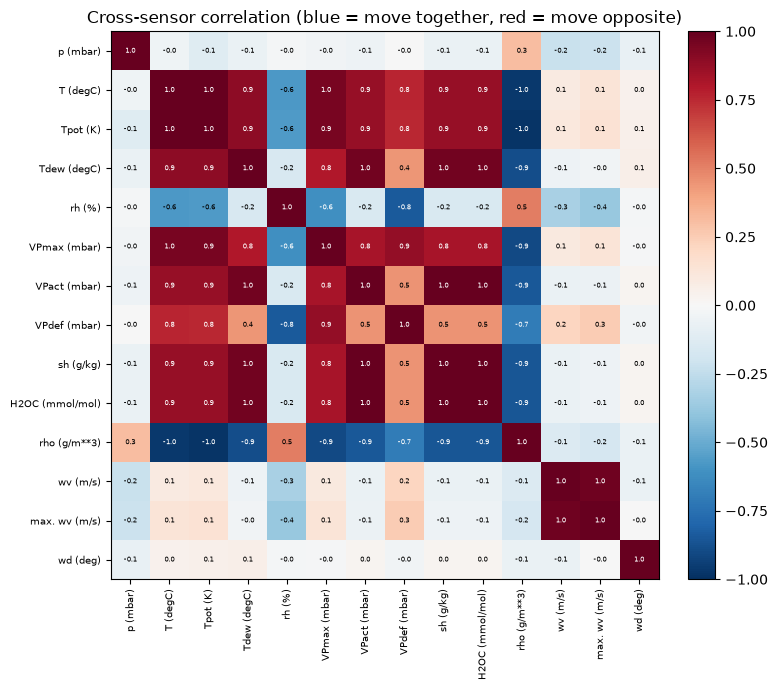

In [30]:
C = df.corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(C, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(S)); ax.set_xticklabels(SENSORS, rotation=90, fontsize=7)
ax.set_yticks(range(S)); ax.set_yticklabels(SENSORS, fontsize=7)
for i in range(S):
    for j in range(S):
        ax.text(j, i, f"{C.iat[i, j]:.1f}", ha='center', va='center',
                fontsize=5.2, color='white' if abs(C.iat[i, j]) > 0.6 else 'black')
ax.set_title("Cross-sensor correlation (blue = move together, red = move opposite)")
plt.colorbar(im, fraction=0.046, pad=0.04); plt.tight_layout(); plt.show()

## The multivariate harness — reconstruct the whole sensor vector

Every architecture is trained the **same way**: standardise **each sensor** to mean 0 / std 1 (so no
channel dominates by unit), slice the 14-channel signal into fixed-length windows `[N, window, 14]`, and
train an **autoencoder** to reconstruct each window. Having learned the joint normal pattern, a model
rebuilds normal windows well and abnormal ones poorly.

Scoring returns a **per-sensor error matrix** `[T, 14]`; the **network anomaly score** at each timestamp is
the mean error across sensors, and the **arg-max sensor** is our attribution ("which sensor looks wrong").
Inference is batched so the full array never sits on the GPU at once.

In [31]:
def get_device():
    return "cuda" if torch.cuda.is_available() else "cpu"
DEVICE = get_device()

def fit_standardiser(frame):
    """Per-sensor (mean, std) learned from the training frame."""
    return frame.mean().to_numpy('float32'), frame.std(ddof=0).to_numpy('float32')

def apply_standardise(frame, mu, sd):
    return ((frame.to_numpy('float32') - mu) / sd).astype('float32')   # [T, S]

def make_windows(Z, window, step):
    """[T, S] -> X[N, window, S] and start positions."""
    starts = list(range(0, len(Z) - window + 1, step))
    X = np.stack([Z[s:s + window] for s in starts]).astype('float32')
    return X, starts

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def train(model, X, epochs=12, lr=1e-3, batch_size=128, seed=42, device=None):
    """Generic reconstruction-autoencoder training loop. Returns (model, loss_history)."""
    device = device or DEVICE
    model = model.to(device)
    torch.manual_seed(seed)
    xt = torch.from_numpy(X.astype('float32'))
    loader = DataLoader(TensorDataset(xt), batch_size=batch_size, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = []
    model.train()
    for _ in range(epochs):
        total = 0.0
        for (batch,) in loader:
            batch = batch.to(device)
            opt.zero_grad()
            loss = loss_fn(model(batch), batch)
            loss.backward(); opt.step()
            total += loss.item() * len(batch)
        history.append(total / len(xt))
    return model, history

def _mean_loss(model, X, batch_size=4096):
    """Average per-element MSE of the model on X (used as the validation loss)."""
    device = next(model.parameters()).device
    model.eval(); tot, n = 0.0, 0
    loss_sum = nn.MSELoss(reduction='sum')
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb = torch.from_numpy(X[i:i + batch_size].astype('float32')).to(device)
            tot += loss_sum(model(xb), xb).item(); n += xb.numel(); del xb
    return tot / n

def train_es(model, X_train, X_val, max_epochs=50, patience=5, min_delta=1e-5,
             lr=1e-3, batch_size=128, seed=42, device=None):
    """Train with EARLY STOPPING on validation reconstruction loss.

    Each epoch we measure the loss on held-out `X_val`; we keep the best-val weights and stop when
    val hasn't improved for `patience` epochs (overfitting = val stops falling while train keeps
    falling). Returns (model_with_best_weights, train_hist, val_hist, best_epoch).
    """
    import copy
    device = device or DEVICE
    model = model.to(device)
    torch.manual_seed(seed)
    xt = torch.from_numpy(X_train.astype('float32'))
    loader = DataLoader(TensorDataset(xt), batch_size=batch_size, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    tr_hist, va_hist = [], []
    best, best_state, best_ep, wait = float('inf'), None, 0, 0
    for ep in range(1, max_epochs + 1):
        model.train(); total = 0.0
        for (batch,) in loader:
            batch = batch.to(device)
            opt.zero_grad()
            loss = loss_fn(model(batch), batch)
            loss.backward(); opt.step()
            total += loss.item() * len(batch)
        tr_hist.append(total / len(xt))
        va = _mean_loss(model, X_val); va_hist.append(va)
        if va < best - min_delta:
            best, best_state, best_ep, wait = va, copy.deepcopy(model.state_dict()), ep, 0
        else:
            wait += 1
            if wait >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)          # restore the best-val weights
    return model, tr_hist, va_hist, best_ep

def _predict_batched(model, X, batch_size=4096):
    device = next(model.parameters()).device
    model.eval(); chunks = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb = torch.from_numpy(X[i:i + batch_size].astype('float32')).to(device)
            chunks.append(model(xb).cpu().numpy()); del xb
    return np.concatenate(chunks, axis=0)

def recon_error_matrix(model, Z, window, score_step=1):
    """Per-timestamp, per-sensor reconstruction error -> [T, S]."""
    Xsc, starts = make_windows(Z, window, score_step)
    recon = _predict_batched(model, Xsc)                 # [N, window, S]
    sq = (Xsc - recon) ** 2
    T, Sd = Z.shape
    err_sum = np.zeros((T, Sd)); err_cnt = np.zeros((T, 1))
    for i, s in enumerate(starts):
        err_sum[s:s + window] += sq[i]; err_cnt[s:s + window] += 1
    return err_sum / np.maximum(err_cnt, 1)

def network_score(err_TS):
    """Mean error across sensors -> per-timestamp anomaly score [T]."""
    return err_TS.mean(axis=1)

def inject_sensor_faults(frame, n=100, magnitude=4.0, seed=42):
    """Simulate n single-sensor faults: at n random timestamps, bump ONE random sensor by
    magnitude*std. Returns (noisy_frame, labels[T], fault_sensor[T] (-1 where none))."""
    rng = np.random.default_rng(seed)
    out = frame.copy()
    stds = frame.std(ddof=0).to_numpy()
    times = rng.choice(len(frame), size=n, replace=False)
    sensors = rng.integers(0, frame.shape[1], size=n)
    signs = rng.choice([-1.0, 1.0], size=n)
    labels = np.zeros(len(frame), bool)
    fault_sensor = np.full(len(frame), -1, int)
    for t, j, sgn in zip(times, sensors, signs):
        out.iat[t, j] += sgn * magnitude * stds[j]
        labels[t] = True; fault_sensor[t] = j
    return out, labels, fault_sensor

print("Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "n/a")

Device: cuda | GPU: NVIDIA GeForce RTX 5070 Laptop GPU


## The five architectures (multivariate)

Each maps a window `[B, window, S]` to a reconstruction of the same shape. The recurrent trio (RNN/GRU/LSTM)
and the CNN squeeze all `S` sensors through a **16-dim latent bottleneck**; the Transformer reconstructs
each position through **self-attention over the window**, letting it relate one sensor's reading to the
others. Hidden width 32 throughout so the counts stay comparable. Every builder takes the channel count so
the same code serves the 14-sensor array (Sec A–C) and the single-sensor runs (Sec D).

In [32]:
HIDDEN, LATENT = 32, 16

def build_rnn_ae(window, channels):
    class RNNAutoencoder(nn.Module):
        def __init__(self):
            super().__init__()
            self.encoder = nn.RNN(channels, HIDDEN, batch_first=True)
            self.to_latent = nn.Linear(HIDDEN, LATENT)
            self.from_latent = nn.Linear(LATENT, HIDDEN)
            self.decoder = nn.RNN(HIDDEN, HIDDEN, batch_first=True)
            self.out = nn.Linear(HIDDEN, channels)
        def forward(self, x):
            _, h = self.encoder(x)
            z = self.to_latent(h[-1])
            d = self.from_latent(z).unsqueeze(1).repeat(1, x.size(1), 1)
            seq, _ = self.decoder(d)
            return self.out(seq)
    return RNNAutoencoder()

def build_gru_ae(window, channels):
    class GRUAutoencoder(nn.Module):
        def __init__(self):
            super().__init__()
            self.encoder = nn.GRU(channels, HIDDEN, batch_first=True)
            self.to_latent = nn.Linear(HIDDEN, LATENT)
            self.from_latent = nn.Linear(LATENT, HIDDEN)
            self.decoder = nn.GRU(HIDDEN, HIDDEN, batch_first=True)
            self.out = nn.Linear(HIDDEN, channels)
        def forward(self, x):
            _, h = self.encoder(x)
            z = self.to_latent(h[-1])
            d = self.from_latent(z).unsqueeze(1).repeat(1, x.size(1), 1)
            seq, _ = self.decoder(d)
            return self.out(seq)
    return GRUAutoencoder()

def build_lstm_ae(window, channels):
    class LSTMAutoencoder(nn.Module):
        def __init__(self):
            super().__init__()
            self.encoder = nn.LSTM(channels, HIDDEN, batch_first=True)
            self.to_latent = nn.Linear(HIDDEN, LATENT)
            self.from_latent = nn.Linear(LATENT, HIDDEN)
            self.decoder = nn.LSTM(HIDDEN, HIDDEN, batch_first=True)
            self.out = nn.Linear(HIDDEN, channels)
        def forward(self, x):
            _, (h, _) = self.encoder(x)
            z = self.to_latent(h[-1])
            d = self.from_latent(z).unsqueeze(1).repeat(1, x.size(1), 1)
            seq, _ = self.decoder(d)
            return self.out(seq)
    return LSTMAutoencoder()

def build_cnn_ae(window, channels):
    class CNNAutoencoder(nn.Module):
        def __init__(self):
            super().__init__()
            self.encoder = nn.Sequential(
                nn.Conv1d(channels, 16, 7, padding=3), nn.ReLU(),
                nn.Conv1d(16, 8, 7, padding=3), nn.ReLU(),
                nn.Flatten(),
                nn.Linear(8 * window, LATENT), nn.ReLU(),
            )
            self.decoder = nn.Sequential(
                nn.Linear(LATENT, 8 * window), nn.ReLU(),
                nn.Unflatten(1, (8, window)),
                nn.Conv1d(8, 16, 7, padding=3), nn.ReLU(),
                nn.Conv1d(16, channels, 7, padding=3),
            )
        def forward(self, x):                              # [B, window, C]
            out = self.decoder(self.encoder(x.transpose(1, 2)))
            return out.transpose(1, 2)
    return CNNAutoencoder()

def build_transformer_ae(window, channels, d_model=32, nhead=4, layers=2, dim_ff=64):
    class PositionalEncoding(nn.Module):
        def __init__(self, d_model, max_len=512):
            super().__init__()
            pe = torch.zeros(max_len, d_model)
            pos = torch.arange(0, max_len).unsqueeze(1).float()
            div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
            pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
            self.register_buffer('pe', pe.unsqueeze(0))
        def forward(self, x):
            return x + self.pe[:, :x.size(1)]
    class TransformerAutoencoder(nn.Module):
        def __init__(self):
            super().__init__()
            self.inp = nn.Linear(channels, d_model)
            self.pos = PositionalEncoding(d_model)
            enc = nn.TransformerEncoderLayer(d_model, nhead, dim_ff, batch_first=True)
            self.encoder = nn.TransformerEncoder(enc, layers)
            self.out = nn.Linear(d_model, channels)
        def forward(self, x):
            return self.out(self.encoder(self.pos(self.inp(x))))
    return TransformerAutoencoder()

ARCHS = {"RNN": build_rnn_ae, "GRU": build_gru_ae, "LSTM": build_lstm_ae,
         "CNN": build_cnn_ae, "Transformer": build_transformer_ae}
print("Architectures:", list(ARCHS))

Architectures: ['RNN', 'GRU', 'LSTM', 'CNN', 'Transformer']


## Section A — Train all five on the full sensor array (with early stopping)

Same window (24 h), same seed. Instead of a fixed epoch count we let each model run **up to 50 epochs** but
**stop early when it overfits**: we hold out the **last 20% of the series** (chronologically — train on the
earlier years, validate on the most recent) and, each epoch, measure the reconstruction loss on that held-out
data. When validation loss stops improving for **5 epochs** (`patience`) we stop and **restore the
best-validation weights**. Overfitting is exactly the point where training loss keeps falling but validation
loss flattens or rises — you'll see that gap in the convergence panels below.

We report where each model stopped and its train/val loss. (Whether the best-*reconstruction* epoch is also
the best-*detection* epoch is a separate question — Section B measures detection on these same early-stopped
models, so the two can be compared honestly.)

In [33]:
WINDOW, MAX_EPOCHS, PATIENCE, SEED = 24, 50, 5, 42
mu, sd = fit_standardiser(df)
Z = apply_standardise(df, mu, sd)                  # [T, S]
Xall, _ = make_windows(Z, WINDOW, step=WINDOW)
n_val = int(len(Xall) * 0.2)
Xtr, Xval = Xall[:-n_val], Xall[-n_val:]           # chronological hold-out (last 20% = validation)
print(f"train windows: {len(Xtr)}  |  val windows: {len(Xval)} (last 20%, chronological)")

# warm up CUDA so the first model isn't charged for context init -> fair timing
if DEVICE == "cuda":
    _w = build_rnn_ae(WINDOW, S).to(DEVICE)
    _l = nn.MSELoss()(_w(torch.zeros(16, WINDOW, S, device=DEVICE)), torch.zeros(16, WINDOW, S, device=DEVICE))
    _l.backward(); torch.cuda.synchronize(); del _w, _l; torch.cuda.empty_cache()

models, tr_hists, va_hists, rows = {}, {}, {}, []
for name, builder in ARCHS.items():
    torch.manual_seed(SEED)                        # seed BEFORE build -> reproducible weight init
    model = builder(WINDOW, S)
    t0 = time.time()
    model, trh, vah, stop_ep = train_es(model, Xtr, Xval, max_epochs=MAX_EPOCHS,
                                        patience=PATIENCE, seed=SEED)
    dt = time.time() - t0
    models[name] = model; tr_hists[name] = trh; va_hists[name] = vah
    rows.append({"arch": name, "params": count_params(model), "train_s": round(dt, 2),
                 "stop_epoch": stop_ep, "epochs_ran": len(trh),
                 "train_loss": round(trh[stop_ep - 1], 5), "val_loss": round(vah[stop_ep - 1], 5)})
    print(f"{name:12s} best@{stop_ep:>2}/{MAX_EPOCHS} (ran {len(trh):>2})  {dt:5.1f}s  "
          f"train={trh[stop_ep-1]:.5f}  val={vah[stop_ep-1]:.5f}")

trainA = pd.DataFrame(rows).set_index("arch")
trainA

train windows: 2338  |  val windows: 584 (last 20%, chronological)
RNN          best@50/50 (ran 50)    1.5s  train=0.15520  val=0.15870
GRU          best@50/50 (ran 50)    1.6s  train=0.10273  val=0.10429
LSTM         best@50/50 (ran 50)    1.8s  train=0.10409  val=0.10676
CNN          best@49/50 (ran 50)    1.3s  train=0.07049  val=0.07155
Transformer  best@50/50 (ran 50)    2.5s  train=0.00383  val=0.00225


,params,train_s,stop_epoch,epochs_ran,train_loss,val_loss
arch,,,,,,
RNN,5182,1.47,50,50,0.15520,0.15870
GRU,12478,1.63,50,50,0.10273,0.10429
LSTM,16126,1.76,50,50,0.10409,0.10676
CNN,11334,1.29,49,50,0.07049,0.07155
Transformer,18030,2.47,50,50,0.00383,0.00225


### Convergence — train vs. validation, and where each model stopped

One panel per model: **train** loss (blue) keeps falling; **validation** loss (red) is the honest signal.
The dashed line marks the restored best-validation epoch. A widening blue–red gap after that line is
overfitting — the reason we stopped.

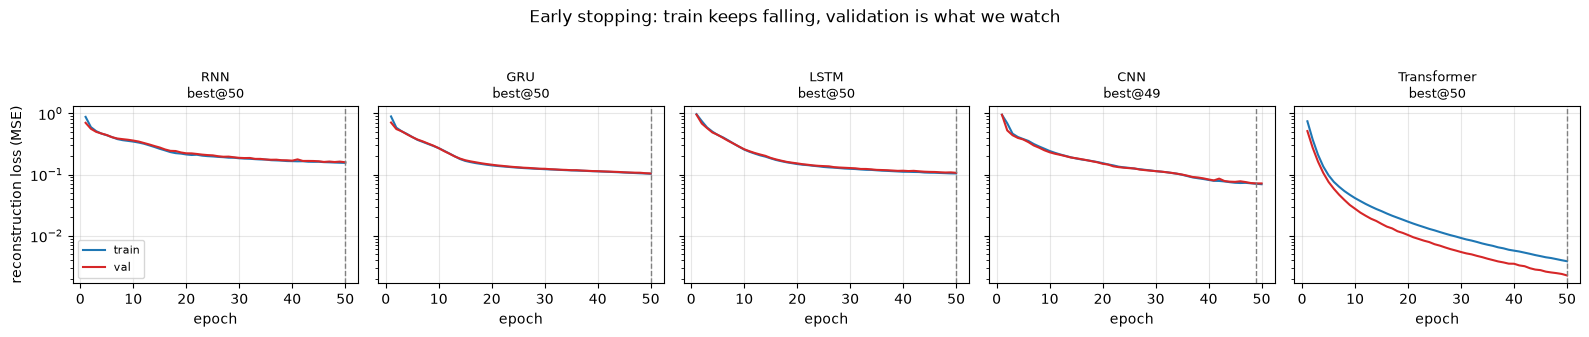

In [34]:
fig, axes = plt.subplots(1, len(models), figsize=(16, 3.2), sharey=True)
for ax, name in zip(axes, models):
    ep = range(1, len(tr_hists[name]) + 1)
    ax.plot(ep, tr_hists[name], color='tab:blue', label='train')
    ax.plot(ep, va_hists[name], color='tab:red', label='val')
    se = int(trainA.loc[name, 'stop_epoch'])
    ax.axvline(se, color='0.5', ls='--', lw=1)
    ax.set_title(f"{name}\nbest@{se}", fontsize=9)
    ax.set_xlabel('epoch'); ax.set_yscale('log'); ax.grid(alpha=0.3)
axes[0].set_ylabel('reconstruction loss (MSE)'); axes[0].legend(fontsize=8)
plt.suptitle("Early stopping: train keeps falling, validation is what we watch", y=1.04)
plt.tight_layout(); plt.show()

### Watching the stopper fire — a scarce-data regime

Above, every model's best-validation epoch was the 50-epoch cap: on the full 70k-row array these small
models **never overfit**, because the data is abundant and the daily pattern is regular. Early stopping
earns its keep when **data is scarce relative to model capacity**. To *see the stopper fire*, we
deliberately create that condition: train a slightly wider GRU (hidden 64) on only **100 windows** (a tiny
slice, sampled across all seasons) and let it run up to **300 epochs**. Now the model has enough capacity
to *memorise* the few training windows — training loss keeps falling while validation loss bottoms out and
**turns back up** (overfitting). The stopper catches that, halts well before 300, and restores the
best-validation weights.

Trained on 100 windows | ran 140/300 epochs before early stop | best-validation epoch = 120 (val=0.1490); train there = 0.0901  ->  train << val = overfitting


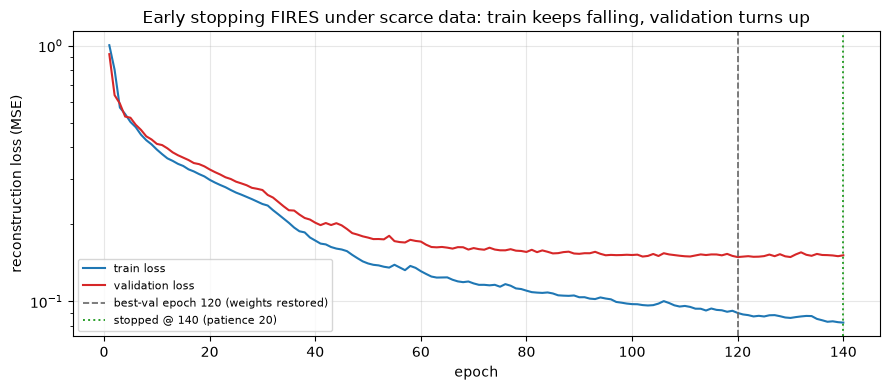

In [35]:
# Force an overfitting regime so early stopping actually triggers.
rng = np.random.default_rng(0)
perm = rng.permutation(len(Xall))            # Xall = all non-overlapping windows (from Section A)
Xtr_small  = Xall[perm[:100]]                # 100 training windows (scarce)
Xval_small = Xall[perm[100:180]]             # 80 held-out validation windows (same distribution)

class WideGRU(nn.Module):                     # hidden 64 -> capacity to memorise 100 windows
    def __init__(self, channels, hidden=64, latent=16):
        super().__init__()
        self.encoder = nn.GRU(channels, hidden, batch_first=True)
        self.to_latent = nn.Linear(hidden, latent)
        self.from_latent = nn.Linear(latent, hidden)
        self.decoder = nn.GRU(hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, channels)
    def forward(self, x):
        _, h = self.encoder(x)
        z = self.to_latent(h[-1])
        d = self.from_latent(z).unsqueeze(1).repeat(1, x.size(1), 1)
        seq, _ = self.decoder(d)
        return self.out(seq)

torch.manual_seed(SEED)
demo = WideGRU(S)
demo, dtr, dva, dstop = train_es(demo, Xtr_small, Xval_small,
                                 max_epochs=300, patience=20, batch_size=16, seed=SEED)
print(f"Trained on {len(Xtr_small)} windows | ran {len(dtr)}/300 epochs before early stop "
      f"| best-validation epoch = {dstop} (val={dva[dstop-1]:.4f}); "
      f"train there = {dtr[dstop-1]:.4f}  ->  train << val = overfitting")

fig, ax = plt.subplots(figsize=(9, 4))
ep = range(1, len(dtr) + 1)
ax.plot(ep, dtr, color='tab:blue', label='train loss')
ax.plot(ep, dva, color='tab:red', label='validation loss')
ax.axvline(dstop, color='0.4', ls='--', lw=1.2, label=f'best-val epoch {dstop} (weights restored)')
ax.axvline(len(dtr), color='tab:green', ls=':', lw=1.4, label=f'stopped @ {len(dtr)} (patience 20)')
ax.set_xlabel('epoch'); ax.set_ylabel('reconstruction loss (MSE)'); ax.set_yscale('log')
ax.set_title('Early stopping FIRES under scarce data: train keeps falling, validation turns up')
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Per-point network anomaly score on real data

Each model's mean-across-sensors error over a two-week window. Where it rises, the model found the joint
sensor reading *surprising* (relative to what it learned as normal).

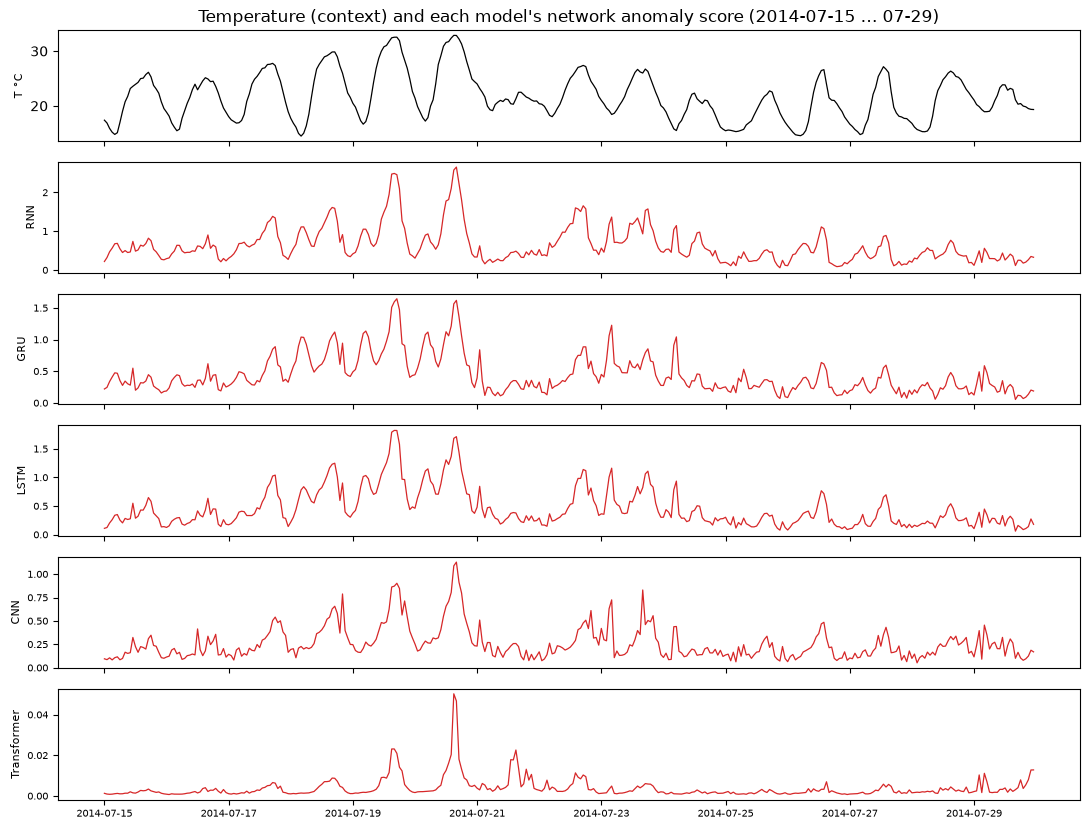

In [36]:
clean_err = {name: recon_error_matrix(m, Z, WINDOW) for name, m in models.items()}
clean_net = {name: pd.Series(network_score(e), index=df.index) for name, e in clean_err.items()}

sl = slice('2014-07-15', '2014-07-29')
fig, axes = plt.subplots(len(models) + 1, 1, figsize=(11, 1.4 * (len(models) + 1)), sharex=True)
axes[0].plot(df['T (degC)'].loc[sl], color='black', lw=0.9); axes[0].set_ylabel("T °C", fontsize=8)
axes[0].set_title("Temperature (context) and each model's network anomaly score (2014-07-15 … 07-29)")
for ax, (name, sc) in zip(axes[1:], clean_net.items()):
    ax.plot(sc.loc[sl], color='tab:red', lw=0.9); ax.set_ylabel(name, fontsize=8)
    ax.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

## Section B — Why they differ, and IoT fault detection

### Agreement between models

Flag the top 0.5% highest network-error timestamps from each model, then measure pairwise **Jaccard
overlap**. High overlap = the architectures agree on what's anomalous across the array; low = they disagree.

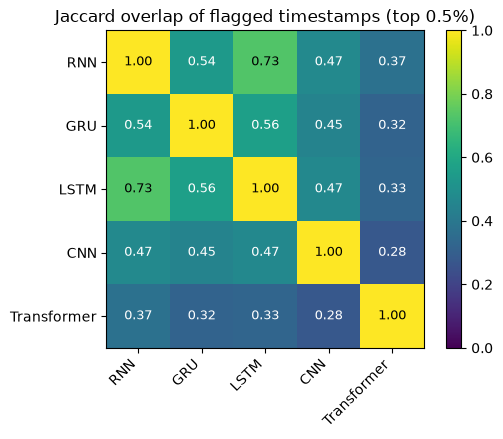

In [37]:
Q = 0.995
clean_flags = {name: (sc > sc.quantile(Q)) for name, sc in clean_net.items()}
names = list(clean_flags)
J = np.zeros((len(names), len(names)))
for i, a in enumerate(names):
    for j, b in enumerate(names):
        A, B = clean_flags[a].values, clean_flags[b].values
        inter = (A & B).sum(); union = (A | B).sum()
        J[i, j] = inter / union if union else 1.0

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(J, vmin=0, vmax=1, cmap='viridis')
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha='right')
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{J[i, j]:.2f}", ha='center', va='center',
                color='white' if J[i, j] < 0.6 else 'black', fontsize=9)
ax.set_title(f"Jaccard overlap of flagged timestamps (top {100*(1-Q):.1f}%)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

### Injecting single-sensor faults (the realistic IoT failure)

We simulate 100 faults where, at a random time, **one** of the 14 sensors jumps by `magnitude·σ` while the
other 13 stay normal — an anemometer sticking, a humidity probe drifting. This is *hard*: the bad channel is
only 1/14 of the network score, so detection now rewards models that understand **cross-sensor consistency**,
not just local spikiness.

We **sweep the fault magnitude** (1σ → 8σ) and measure **Average Precision** per architecture — where the
curves cross is where the inductive biases genuinely differ. The tables report a hard **4σ operating point**.
All computed by scikit-learn. No LLM.

In [38]:
MAGS = [1, 2, 3, 4, 6, 8]
HARD_MAG = 4.0

def net_score_on_faults(model, window, magnitude):
    noisy, labels, fault = inject_sensor_faults(df, n=100, magnitude=magnitude, seed=42)
    Zn = apply_standardise(noisy, mu, sd)            # SAME per-sensor (mu, sd) as training
    err = recon_error_matrix(model, Zn, window)
    return network_score(err), labels, fault

def ap_on_faults(model, window, magnitude):
    sc, labels, _ = net_score_on_faults(model, window, magnitude)
    return average_precision_score(labels, sc)

sweep = {name: [ap_on_faults(m, WINDOW, mg) for mg in MAGS] for name, m in models.items()}

eval_rows = []
for name, m in models.items():
    sc, labels, _ = net_score_on_faults(m, WINDOW, HARD_MAG)
    N = int(labels.sum()); thr = np.sort(sc)[-N]
    pred = sc >= thr
    tp = int((pred & labels).sum()); fp = int((pred & ~labels).sum()); fn = int((~pred & labels).sum())
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
    eval_rows.append({"arch": name,
                      "AUC@4s": round(roc_auc_score(labels, sc), 3),
                      "AP@4s": round(average_precision_score(labels, sc), 3),
                      "F1@topN": round(f1, 3)})
evalB = pd.DataFrame(eval_rows).set_index("arch")
summary = trainA.join(evalB).sort_values("AP@4s", ascending=False)
print(f"Ranked by Average Precision at the hard {HARD_MAG}-sigma single-sensor fault:")
summary

Ranked by Average Precision at the hard 4.0-sigma single-sensor fault:


,params,train_s,stop_epoch,epochs_ran,train_loss,val_loss,AUC@4s,AP@4s,F1@topN
arch,,,,,,,,,
Transformer,18030,2.47,50,50,0.00383,0.00225,1.000,0.835,0.80
CNN,11334,1.29,49,50,0.07049,0.07155,0.999,0.454,0.50
GRU,12478,1.63,50,50,0.10273,0.10429,0.996,0.151,0.10
LSTM,16126,1.76,50,50,0.10409,0.10676,0.993,0.093,0.02
RNN,5182,1.47,50,50,0.15520,0.15870,0.987,0.054,0.01


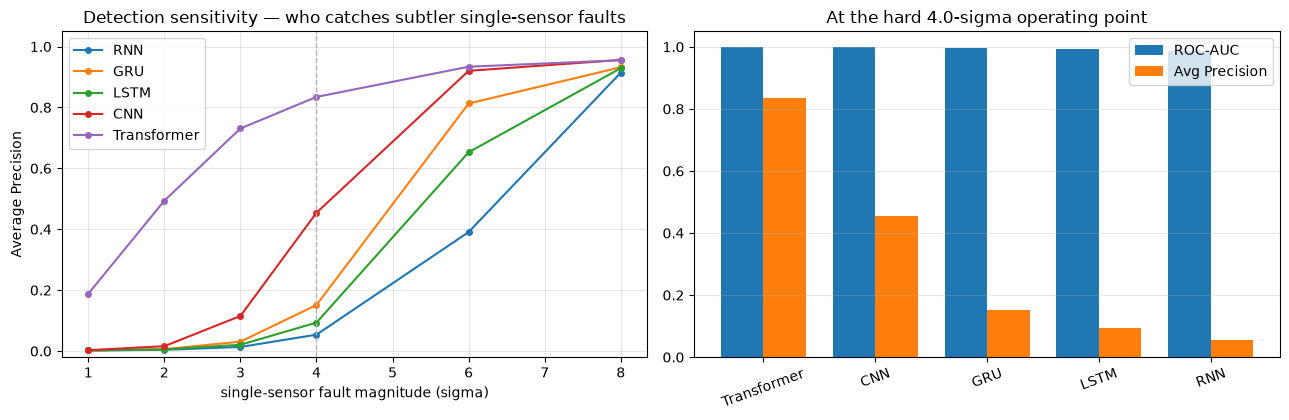

In [39]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
for name in models:
    ax1.plot(MAGS, sweep[name], marker='o', ms=4, label=name)
ax1.axvline(HARD_MAG, color='0.7', ls='--', lw=1)
ax1.set_xlabel("single-sensor fault magnitude (sigma)"); ax1.set_ylabel("Average Precision")
ax1.set_ylim(-0.02, 1.05)
ax1.set_title("Detection sensitivity — who catches subtler single-sensor faults")
ax1.legend(); ax1.grid(alpha=0.3)
x = np.arange(len(summary)); w = 0.38
ax2.bar(x - w/2, summary["AUC@4s"], w, label="ROC-AUC")
ax2.bar(x + w/2, summary["AP@4s"], w, label="Avg Precision")
ax2.set_xticks(x); ax2.set_xticklabels(summary.index, rotation=20); ax2.set_ylim(0, 1.05)
ax2.set_title(f"At the hard {HARD_MAG}-sigma operating point")
ax2.legend(); ax2.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

### Which sensor faulted? — attribution (computed, no LLM)

Detection says *when*; a useful IoT monitor also says *which sensor*. For each injected fault we take the
**arg-max sensor** of the per-sensor error matrix and check it against the sensor we actually corrupted.
Attribution accuracy = fraction identified correctly (chance = 1/14 ≈ 0.07). We sweep the fault magnitude:
at a clear 6σ fault every model pinpoints the sensor perfectly, but as faults get subtle the models that
understand cross-sensor structure keep attributing correctly for longer.

In [40]:
def attribution_acc(model, magnitude):
    noisy, labels, fault = inject_sensor_faults(df, n=100, magnitude=magnitude, seed=42)
    Zn = apply_standardise(noisy, mu, sd)
    idx = np.where(labels)[0]
    err = recon_error_matrix(model, Zn, WINDOW)
    return float((err[idx].argmax(axis=1) == fault[idx]).mean())

ATTR_MAGS = [2, 3, 4, 6]
attr = {mg: {name: round(attribution_acc(m, mg), 3) for name, m in models.items()} for mg in ATTR_MAGS}
attrB = pd.DataFrame(attr).T; attrB.index.name = "fault_sigma"
print(f"Attribution accuracy (chance = {1/S:.3f}):")
attrB

Attribution accuracy (chance = 0.071):


,RNN,GRU,LSTM,CNN,Transformer
fault_sigma,,,,,
2,0.94,0.95,0.96,0.99,0.85
3,0.98,1.00,0.99,1.00,0.95
4,1.00,1.00,1.00,1.00,0.96
6,1.00,1.00,1.00,1.00,0.99


## Section C — Training technique (multivariate GRU)

Fixing the architecture to **GRU** and varying two training choices, to show the result is not the
architecture alone. Detection is measured at the same hard **4σ single-sensor fault** as Section B. Here we
train to a **fixed epoch count** (no early stopping) so each *knob* is the only thing changing — the epoch
sweep below is precisely the thing early stopping (Section A) automates.

### Window size — how much history the model sees per step

In [41]:
def eval_config(builder, window, epochs, magnitude=HARD_MAG, seed=42):
    Zc = apply_standardise(df, mu, sd)
    Xw, _ = make_windows(Zc, window, step=window)
    torch.manual_seed(seed); model = builder(window, S)
    t0 = time.time(); model, hist = train(model, Xw, epochs=epochs, seed=seed); dt = time.time() - t0
    sc, labels, _ = net_score_on_faults(model, window, magnitude)
    thr = np.sort(sc)[-int(labels.sum())]; pred = sc >= thr
    tp = int((pred & labels).sum()); fp = int((pred & ~labels).sum()); fn = int((~pred & labels).sum())
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
    return {"AUC": round(roc_auc_score(labels, sc), 3), "AP": round(average_precision_score(labels, sc), 3),
            "F1@topN": round(f1, 3), "final_loss": round(hist[-1], 5), "train_s": round(dt, 2)}

FIXED_EPOCHS = 20                                  # fixed budget so the *window* is the only variable
win_rows = []
for w in [12, 24, 48]:
    r = eval_config(build_gru_ae, w, FIXED_EPOCHS); r["window"] = w; win_rows.append(r)
    print(f"window={w:2d}  AUC={r['AUC']}  AP={r['AP']}  F1@topN={r['F1@topN']}  loss={r['final_loss']}")
winC = pd.DataFrame(win_rows).set_index("window")[["train_s", "final_loss", "AUC", "AP", "F1@topN"]]
winC

window=12  AUC=1.0  AP=0.769  F1@topN=0.85  loss=0.0744
window=24  AUC=0.992  AP=0.08  F1@topN=0.01  loss=0.12947
window=48  AUC=0.984  AP=0.041  F1@topN=0.0  loss=0.32997


,train_s,final_loss,AUC,AP,F1@topN
window,,,,,
12,1.39,0.07440,1.000,0.769,0.85
24,0.74,0.12947,0.992,0.080,0.01
48,0.39,0.32997,0.984,0.041,0.00


### Training length — how many epochs

epochs= 3  final_loss=0.48918  AP=0.02
epochs= 6  final_loss=0.33670  AP=0.032
epochs=12  final_loss=0.17206  AP=0.053
epochs=24  final_loss=0.12222  AP=0.094


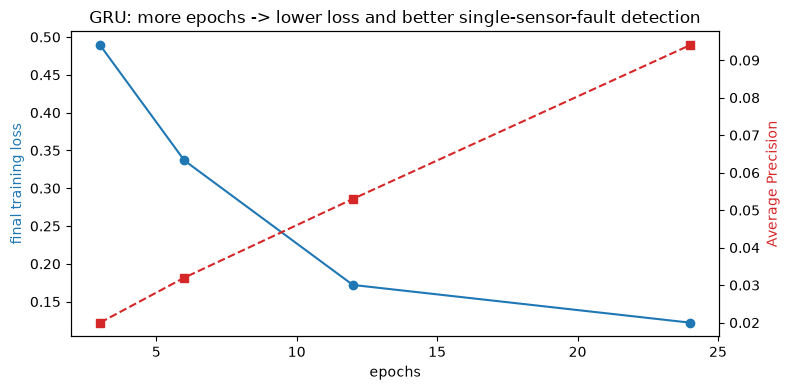

,final_loss,AP
epochs,,
3,0.48918,0.020
6,0.33670,0.032
12,0.17206,0.053
24,0.12222,0.094


In [42]:
ep_hist = {}
for ep in [3, 6, 12, 24]:
    Zc = apply_standardise(df, mu, sd)
    Xw, _ = make_windows(Zc, WINDOW, step=WINDOW)
    torch.manual_seed(SEED); m = build_gru_ae(WINDOW, S)
    m, hist = train(m, Xw, epochs=ep, seed=SEED)
    sc, labels, _ = net_score_on_faults(m, WINDOW, HARD_MAG)
    ep_hist[ep] = {"final_loss": round(hist[-1], 5), "AP": round(average_precision_score(labels, sc), 3)}
    print(f"epochs={ep:2d}  final_loss={hist[-1]:.5f}  AP={ep_hist[ep]['AP']}")
epC = pd.DataFrame(ep_hist).T; epC.index.name = "epochs"

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(epC.index, epC["final_loss"], 'o-', color='tab:blue', label='final loss')
ax1.set_xlabel("epochs"); ax1.set_ylabel("final training loss", color='tab:blue')
ax2 = ax1.twinx(); ax2.plot(epC.index, epC["AP"], 's--', color='tab:red', label='AP')
ax2.set_ylabel("Average Precision", color='tab:red')
ax1.set_title("GRU: more epochs -> lower loss and better single-sensor-fault detection")
plt.tight_layout(); plt.show()
epC

## Section D — Per-sensor modelability (not all sensors are equal)

The joint model is only as good as its channels. Here we train the **CNN autoencoder on each sensor
individually** (univariate) and read off two things per sensor: the **final reconstruction loss** (how
learnable its normal pattern is) and the **detection AP** for a 1σ spike in that channel. Smooth,
strongly-coupled sensors are easy; noisy, near-independent ones (the wind channels) are hard — which tells
us where an IoT monitor is least reliable.

In [43]:
persensor = []
for j, name in enumerate(SENSORS):
    col = df[[name]]
    muj, sdj = fit_standardiser(col)
    Zj = apply_standardise(col, muj, sdj)
    Xj, _ = make_windows(Zj, WINDOW, step=WINDOW)
    torch.manual_seed(SEED); mj = build_cnn_ae(WINDOW, 1)
    mj, hist = train(mj, Xj, epochs=10, seed=SEED)
    noisy, labels, _ = inject_sensor_faults(col, n=100, magnitude=1.0, seed=42)
    Zn = apply_standardise(noisy, muj, sdj)
    sc = network_score(recon_error_matrix(mj, Zn, WINDOW))
    persensor.append({"sensor": name, "family": INFO[name][2],
                      "final_loss": round(hist[-1], 4),
                      "AP@1s": round(average_precision_score(labels, sc), 3)})
    del mj
    if DEVICE == "cuda": torch.cuda.empty_cache()
psD = pd.DataFrame(persensor).set_index("sensor")
psD_sorted = psD.sort_values("AP@1s", ascending=False)
print("Per-sensor modelability (CNN, univariate):")
psD_sorted

Per-sensor modelability (CNN, univariate):


,family,final_loss,AP@1s
sensor,,,
Tdew (degC),Temperature,0.0093,0.999
sh (g/kg),Humidity,0.0121,0.906
VPact (mbar),Humidity,0.0125,0.903
H2OC (mmol/mol),Humidity,0.0132,0.900
p (mbar),Pressure,0.0056,0.885
rho (g/m**3),Density,0.0149,0.793
Tpot (K),Temperature,0.0141,0.648
T (degC),Temperature,0.0147,0.528
rh (%),Humidity,0.0327,0.194


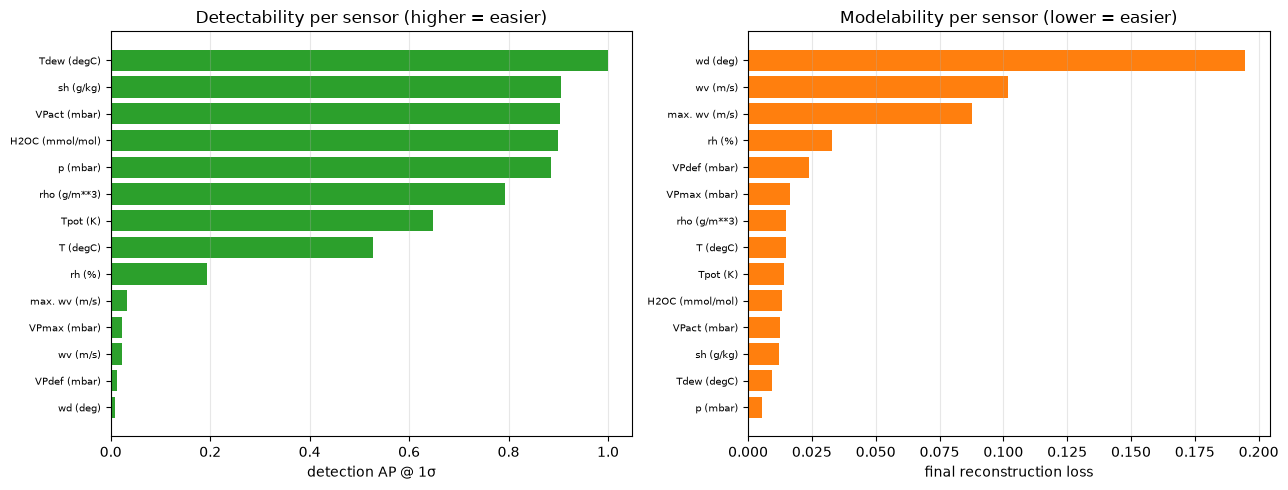

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
order = psD.sort_values("AP@1s", ascending=True).index
ax1.barh(range(S), psD.loc[order, "AP@1s"], color='tab:green')
ax1.set_yticks(range(S)); ax1.set_yticklabels(order, fontsize=7)
ax1.set_xlabel("detection AP @ 1σ"); ax1.set_title("Detectability per sensor (higher = easier)")
ax1.grid(axis='x', alpha=0.3)
order2 = psD.sort_values("final_loss", ascending=True).index
ax2.barh(range(S), psD.loc[order2, "final_loss"], color='tab:orange')
ax2.set_yticks(range(S)); ax2.set_yticklabels(order2, fontsize=7)
ax2.set_xlabel("final reconstruction loss"); ax2.set_title("Modelability per sensor (lower = easier)")
ax2.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

## Section E — Best classical / ML techniques vs the deep nets

The deep autoencoders read a **24-hour temporal window**. But a single-sensor fault is really a
**cross-sectional** event: at one instant, one channel disagrees with the other 13. So we now pit the deep
nets against five strong **classical detectors** that read only the **instantaneous 14-sensor vector** —
no windows, no training loop — on the *exact same* injected-fault evaluation:

- **PCA reconstruction** — a *linear* autoencoder: project onto the top principal components and back; big
  residual = off-structure point.
- **Mahalanobis distance** — distance from the normal joint distribution using the (shrunk) covariance; a
  value inconsistent with its correlated neighbours is far away.
- **Isolation Forest** — random splits isolate outliers in fewer cuts.
- **LOF** — local density vs. neighbours.
- **One-Class SVM** — a learned boundary around normal data.

The question: does a simple statistical model beat a Transformer when the anomaly is a linear cross-sensor
inconsistency? Every number computed by scikit-learn. No LLM.

> **This cell:** fits all five classical detectors on the *clean* standardised sensor vectors (learn
> normal), then defines `classical_scores` returning a per-timestamp anomaly score for each. LOF and
> One-Class SVM are fit on a 5,000-point random subsample (they scale poorly to 70k). PCA keeps 5
> components (~98% of the variance); Mahalanobis uses a Ledoit-Wolf **shrunk** covariance for stability
> given the near-collinear sensors.

In [45]:
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

# All classical detectors read the INSTANTANEOUS 14-sensor vector (cross-sectional), fit on clean data.
_pca = PCA(n_components=5).fit(Z)                       # linear autoencoder; 5 comps ~98% variance
_cov = LedoitWolf().fit(Z)                              # mean + shrunk covariance -> Mahalanobis
_iso = IsolationForest(n_estimators=200, random_state=0).fit(Z)
_sub = np.random.default_rng(0).choice(len(Z), 5000, replace=False)   # subsample for the O(n^2) ones
_lof = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(Z[_sub])
_ocs = OneClassSVM(nu=0.05, gamma='scale').fit(Z[_sub])

def classical_scores(Zn):
    """Per-timestamp anomaly score (higher = more anomalous) for each classical detector."""
    rec = _pca.inverse_transform(_pca.transform(Zn))
    return {"PCA": ((Zn - rec) ** 2).sum(1),
            "Mahalanobis": _cov.mahalanobis(Zn),
            "IsoForest": -_iso.score_samples(Zn),
            "LOF": -_lof.score_samples(Zn),
            "OC-SVM": -_ocs.decision_function(Zn)}

print("PCA variance captured by 5 components:", round(float(_pca.explained_variance_ratio_.sum()), 4))
print("classical detectors fitted:", list(classical_scores(Z)))

PCA variance captured by 5 components: 0.9811
classical detectors fitted: ['PCA', 'Mahalanobis', 'IsoForest', 'LOF', 'OC-SVM']


> **This cell:** runs the same injected-fault evaluation as Section B on all five classical detectors — a
> magnitude sweep (`sweep_cl`) and the hard 4σ operating point — then **merges** them with the deep-net
> results (`summary`) into one ranked table `allm`. Read the `AP@4s` column top-to-bottom: this is the
> head-to-head ranking of *every* technique, deep and classical, on the identical task.

In [46]:
CLASSICAL = ["PCA", "Mahalanobis", "IsoForest", "LOF", "OC-SVM"]

def classical_on_faults(name, magnitude):
    noisy, labels, _ = inject_sensor_faults(df, n=100, magnitude=magnitude, seed=42)
    return classical_scores(apply_standardise(noisy, mu, sd))[name], labels

# magnitude sweep (same MAGS as the deep sweep)
sweep_cl = {name: [average_precision_score(*(lambda s, l: (l, s))(*classical_on_faults(name, mg)))
                   for mg in MAGS] for name in CLASSICAL}

# hard 4-sigma table
rows = []
for name in CLASSICAL:
    sc, labels = classical_on_faults(name, HARD_MAG)
    N = int(labels.sum()); thr = np.sort(sc)[-N]; pred = sc >= thr
    tp = int((pred & labels).sum()); fp = int((pred & ~labels).sum()); fn = int((~pred & labels).sum())
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
    rows.append({"method": name, "family": "classical", "AUC@4s": round(roc_auc_score(labels, sc), 3),
                 "AP@4s": round(average_precision_score(labels, sc), 3), "F1@topN": round(f1, 3)})
clas = pd.DataFrame(rows).set_index("method")

deep = summary[["AUC@4s", "AP@4s", "F1@topN"]].copy(); deep.insert(0, "family", "deep")
allm = pd.concat([deep, clas]).sort_values("AP@4s", ascending=False)
print("All techniques ranked by Average Precision at the hard 4-sigma single-sensor fault:")
allm

All techniques ranked by Average Precision at the hard 4-sigma single-sensor fault:


,family,AUC@4s,AP@4s,F1@topN
Mahalanobis,classical,0.996,0.931,0.91
LOF,classical,1.000,0.894,0.88
Transformer,deep,1.000,0.835,0.80
PCA,classical,0.972,0.544,0.71
OC-SVM,classical,0.999,0.507,0.62
CNN,deep,0.999,0.454,0.50
GRU,deep,0.996,0.151,0.10
LSTM,deep,0.993,0.093,0.02
RNN,deep,0.987,0.054,0.01
IsoForest,classical,0.755,0.003,0.00


> **This cell:** two views of the head-to-head. Left — the sensitivity sweep with **deep nets dashed** and
> **classical solid**, so you can see which method catches the *subtlest* faults (up-and-left is best).
> Right — a ranked bar of AP@4σ coloured by family (**red = classical, blue = deep**). If a red bar tops
> the chart, a classical method beat every neural net.

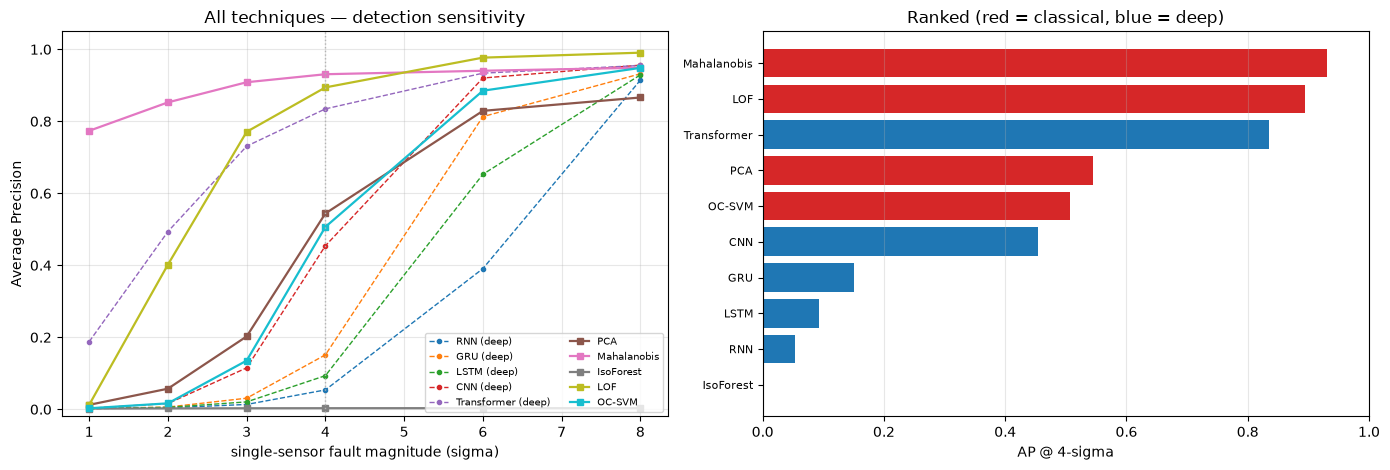

In [47]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for name in models:
    ax1.plot(MAGS, sweep[name], marker='o', ms=3, ls='--', lw=1, label=f"{name} (deep)")
for name in CLASSICAL:
    ax1.plot(MAGS, sweep_cl[name], marker='s', ms=4, lw=1.6, label=name)
ax1.axvline(HARD_MAG, color='0.7', ls=':', lw=1)
ax1.set_xlabel("single-sensor fault magnitude (sigma)"); ax1.set_ylabel("Average Precision")
ax1.set_ylim(-0.02, 1.05); ax1.set_title("All techniques — detection sensitivity")
ax1.legend(fontsize=7, ncol=2); ax1.grid(alpha=0.3)

allm2 = allm.sort_values("AP@4s")
colors = ['tab:red' if f == 'classical' else 'tab:blue' for f in allm2['family']]
ax2.barh(range(len(allm2)), allm2["AP@4s"], color=colors)
ax2.set_yticks(range(len(allm2))); ax2.set_yticklabels(allm2.index, fontsize=8)
ax2.set_xlabel("AP @ 4-sigma"); ax2.set_xlim(0, 1.0)
ax2.set_title("Ranked (red = classical, blue = deep)"); ax2.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

### Finding

**Two classical detectors beat every neural net** at the 4σ single-sensor fault: **Mahalanobis 0.93 > LOF 0.89 > Transformer 0.835 > … > Isolation Forest 0.003** — the fault is a cross-sectional inconsistency a covariance model captures best.

## Section F — Temporal fault types: do the deep nets reclaim the lead?

Section E used **point spikes**, a cross-sectional fault where the covariance model (Mahalanobis) dominates.
But real sensors fail in **temporal** ways too. We now test three classic IoT failures and ask the obvious
question: *since these are temporal, do the deep temporal nets finally win?*

- **Drift** — a sensor ramps away from truth over 24 h (0 → 4σ).
- **Stuck** — a sensor freezes at one value for 24 h (a flat-line; the reading stays in range but stops moving).
- **Global freeze** — *all* sensors freeze together for 24 h (a data-logger hang): every instant is a genuine
  past vector, so it stays **cross-sectionally plausible** — the purest temporal fault.

Same 10 detectors, same AP metric. Faults span a 24 h window, so every timestamp inside it is labelled anomalous.

> **This cell:** defines the two new fault injectors — `inject_drift` (a linear ramp on one sensor) and
> `inject_stuck` (freeze one sensor, or all with `glob=True`). Each returns the corrupted frame and a boolean
> label over the 24 h fault window.

In [48]:
def inject_drift(frame, n=100, magnitude=4.0, length=24, seed=1):
    """Ramp one random sensor from 0 to magnitude*sigma over `length` hours, n times."""
    rng = np.random.default_rng(seed); arr = frame.to_numpy().copy(); stds = frame.std(ddof=0).to_numpy()
    labels = np.zeros(len(frame), bool); ramp = np.linspace(0, 1, length)
    starts = rng.choice(len(frame) - length, n, replace=False)
    js = rng.integers(0, frame.shape[1], n); sgn = rng.choice([-1.0, 1.0], n)
    for s0, j, g in zip(starts, js, sgn):
        arr[s0:s0+length, j] += g * magnitude * stds[j] * ramp; labels[s0:s0+length] = True
    return pd.DataFrame(arr, index=frame.index, columns=frame.columns), labels

def inject_stuck(frame, n=100, length=24, seed=1, glob=False):
    """Freeze one sensor (or all, if glob) at its start value for `length` hours, n times."""
    rng = np.random.default_rng(seed); arr = frame.to_numpy().copy(); labels = np.zeros(len(frame), bool)
    starts = rng.choice(len(frame) - length, n, replace=False); js = rng.integers(0, frame.shape[1], n)
    for s0, j in zip(starts, js):
        if glob: arr[s0:s0+length, :] = arr[s0, :]
        else:    arr[s0:s0+length, j] = arr[s0, j]
        labels[s0:s0+length] = True
    return pd.DataFrame(arr, index=frame.index, columns=frame.columns), labels

print("injectors ready: drift, stuck (single & global)")

injectors ready: drift, stuck (single & global)


> **This cell:** scores **every** detector (5 deep + 5 classical) on each fault type and builds the table
> `faultF` (rows = methods, columns = fault types, values = AP). The `spike` column reuses the Section-E point
> fault as a baseline. Read across a row to see how a method copes as the fault becomes more temporal.

In [49]:
def ap_all_methods(frame, labels):
    Zn = apply_standardise(frame, mu, sd)
    out = {name: average_precision_score(labels, network_score(recon_error_matrix(m, Zn, WINDOW)))
           for name, m in models.items()}
    for name, sc in classical_scores(Zn).items():
        out[name] = average_precision_score(labels, sc)
    return out

pn, pl, _ = inject_sensor_faults(df, n=100, magnitude=4.0, seed=42)
faults = {"spike (4s)":        (pn, pl),
          "drift (4s,24h)":     inject_drift(df, 100, 4.0, 24, seed=1),
          "stuck (24h)":        inject_stuck(df, 100, 24, seed=1, glob=False),
          "global freeze (24h)": inject_stuck(df, 100, 24, seed=1, glob=True)}

faultF = pd.DataFrame({ft: ap_all_methods(fr, lb) for ft, (fr, lb) in faults.items()}).round(3)
faultF.insert(0, "family", ["deep" if k in models else "classical" for k in faultF.index])
faultF = faultF.sort_values("spike (4s)", ascending=False)
print("Detection AP by method x fault type:")
faultF

Detection AP by method x fault type:


,family,spike (4s),"drift (4s,24h)",stuck (24h),global freeze (24h)
Mahalanobis,classical,0.931,0.880,0.642,0.047
LOF,classical,0.894,0.702,0.112,0.040
Transformer,deep,0.835,0.853,0.346,0.036
PCA,classical,0.544,0.539,0.087,0.043
OC-SVM,classical,0.507,0.419,0.052,0.045
CNN,deep,0.454,0.355,0.048,0.023
GRU,deep,0.151,0.211,0.043,0.023
LSTM,deep,0.093,0.248,0.044,0.026
RNN,deep,0.054,0.334,0.056,0.028
IsoForest,classical,0.003,0.048,0.039,0.041


> **This cell:** a heatmap of the table — method (row) × fault type (column), brighter = better detection.
> Scan the **stuck** and **global-freeze** columns: dark almost everywhere is the finding — most detectors,
> and *all* reconstruction autoencoders, go blind on frozen sensors.

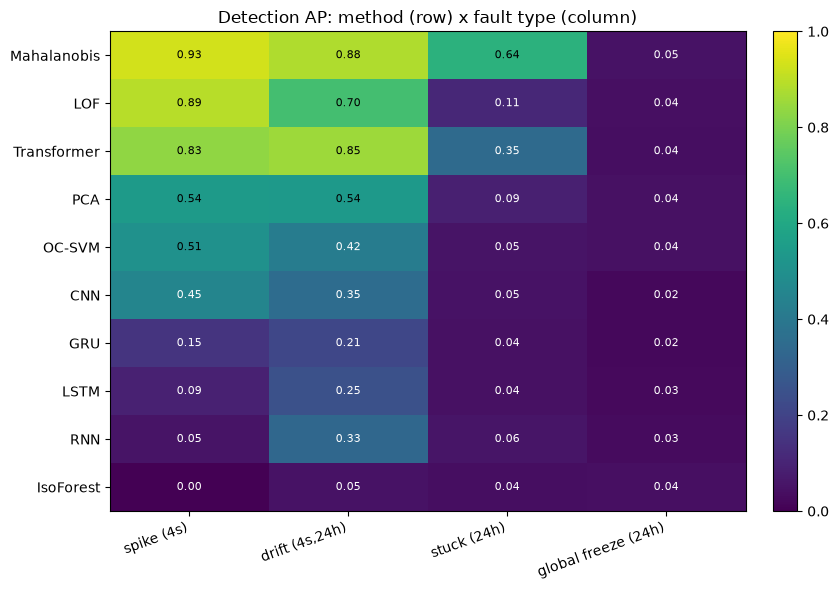

In [50]:
ft_cols = [c for c in faultF.columns if c != "family"]
Mv = faultF[ft_cols].to_numpy()
fig, ax = plt.subplots(figsize=(8.5, 6))
im = ax.imshow(Mv, vmin=0, vmax=1, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(ft_cols))); ax.set_xticklabels(ft_cols, rotation=20, ha="right")
ax.set_yticks(range(len(faultF))); ax.set_yticklabels(faultF.index)
for i in range(len(faultF)):
    for j in range(len(ft_cols)):
        ax.text(j, i, f"{Mv[i, j]:.2f}", ha="center", va="center",
                color="white" if Mv[i, j] < 0.5 else "black", fontsize=8)
ax.set_title("Detection AP: method (row) x fault type (column)")
plt.colorbar(im, fraction=0.046, pad=0.04); plt.tight_layout(); plt.show()

### Finding

**Temporal faults don't rescue the deep nets.** Mahalanobis still wins drift (0.88) and stuck (0.64); reconstruction AEs are blind to frozen sensors (≈base rate); a global freeze fools everyone.

## Section G — The rematch: forecasting and a flat-line detector

A learned **forecaster**, a naive **persistence** baseline, and a purpose-built **flat-line/variance** detector, versus Mahalanobis and the Transformer on the same faults.

> **This cell:** trains a GRU next-step forecaster and defines `forecast_score`, `persistence_score`, and `flatline_score`.

In [51]:
# The rematch detectors: a learned forecaster, a persistence baseline, and a flat-line/variance detector.
VARW = 4  # short variance window so a freeze is spotted quickly

class GRUForecaster(nn.Module):                       # predict the next 14-sensor vector from a window
    def __init__(self, channels, hidden=32):
        super().__init__(); self.gru = nn.GRU(channels, hidden, batch_first=True); self.out = nn.Linear(hidden, channels)
    def forward(self, x):
        _, h = self.gru(x); return self.out(h[-1])

def _pairs(Zarr, w):
    starts = list(range(0, len(Zarr) - w))
    X = np.stack([Zarr[s:s+w] for s in starts]).astype('float32')
    y = np.stack([Zarr[s+w] for s in starts]).astype('float32')
    return X, y, [s + w for s in starts]

_Xf, _yf, _ = _pairs(Z, WINDOW); _ntr = int(len(_Xf) * 0.8)
torch.manual_seed(SEED); _fc = GRUForecaster(S).to(DEVICE)
_opt = torch.optim.Adam(_fc.parameters(), 1e-3); _lf = nn.MSELoss()
_ld = DataLoader(TensorDataset(torch.from_numpy(_Xf[:_ntr]), torch.from_numpy(_yf[:_ntr])), batch_size=256, shuffle=True)
for _ in range(40):
    _fc.train()
    for xb, yb in _ld:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE); _opt.zero_grad(); _lf(_fc(xb), yb).backward(); _opt.step()

def forecast_score(Zn):
    X, y, tgt = _pairs(Zn, WINDOW); _fc.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), 8192):
            out.append(_fc(torch.from_numpy(X[i:i+8192]).to(DEVICE)).cpu().numpy())
    err = ((y - np.concatenate(out)) ** 2).mean(1); sc = np.zeros(len(Zn)); sc[tgt] = err; return sc

def persistence_score(Zn):
    d = np.zeros(len(Zn)); d[1:] = ((Zn[1:] - Zn[:-1]) ** 2).mean(1); return d

_flat_base = pd.DataFrame(Z).rolling(VARW).std().median().to_numpy() + 1e-6
def flatline_score(Zn):
    rstd = pd.DataFrame(Zn).rolling(VARW).std().to_numpy()
    sc = -np.nanmin(rstd / _flat_base, axis=1)
    m = np.nanmin(sc[~np.isnan(sc)]); sc[np.isnan(sc)] = m; return sc

print("Section G ready: forecast_score, persistence_score, flatline_score")

Section G ready: forecast_score, persistence_score, flatline_score


> **This cell:** scores the three new detectors + Mahalanobis + Transformer on all four fault types into `rematch`.

In [52]:
detectors = {
    "Transformer (recon)": lambda Zn: network_score(recon_error_matrix(models["Transformer"], Zn, WINDOW)),
    "Mahalanobis":         lambda Zn: _cov.mahalanobis(Zn),
    "Forecast (GRU)":      forecast_score,
    "Persistence":         persistence_score,
    "Flatline (var)":      flatline_score,
}
rematch = pd.DataFrame({ft: {name: average_precision_score(lb, fn(apply_standardise(fr, mu, sd)))
                             for name, fn in detectors.items()}
                        for ft, (fr, lb) in faults.items()}).round(3)
print("Detection AP - the rematch:")
rematch

Detection AP - the rematch:


,spike (4s),"drift (4s,24h)",stuck (24h),global freeze (24h)
Transformer (recon),0.835,0.853,0.346,0.036
Mahalanobis,0.931,0.880,0.642,0.047
Forecast (GRU),0.535,0.270,0.046,0.020
Persistence,0.284,0.036,0.033,0.033
Flatline (var),0.001,0.033,0.791,0.862


## Section H — Genuinely temporal faults: do the deep nets ever win?

Every fault so far was either **cross-sectional** (covariance's turf) or a **flat-line** (variance's turf). Here
we build the faults *designed* to be purely temporal — where a sequence model *should* have the edge — and test
it honestly:

- **Phase shift** — replay the array (or one sensor) from `Δ` hours earlier: a time/clock drift. Each instant is
  a real reading (cross-sectionally plausible) and variance is normal.
- **Time reversal** — play a 24 h window backwards: temporal order wrong, but marginals and smoothness intact.
- **Oscillation** — a common-mode high-frequency tremor added to all sensors: an out-of-distribution *shape*
  that is genuinely unpredictable step to step.

We reuse the already-trained Transformer, GRU-AE, and the Section-G forecaster, versus Mahalanobis and the
flat-line detector.

> **This cell:** defines the three temporal-fault injectors — `inject_phase` (global or single-sensor time
> shift), `inject_reversal` (play a window backwards), and `inject_oscillation` (common-mode tremor). Each
> returns the corrupted frame and a label over the 24 h fault window.

In [53]:
def inject_phase(frame, n=100, delta=12, length=24, seed=3, single=False):
    """Replay a window from `delta` hours earlier — the whole array (clock drift) or one sensor."""
    rng = np.random.default_rng(seed); arr = frame.to_numpy().copy(); lab = np.zeros(len(frame), bool)
    starts = rng.choice(np.arange(delta, len(frame) - length), n, replace=False)
    js = rng.integers(0, frame.shape[1], n)
    for s0, j in zip(starts, js):
        if single: arr[s0:s0+length, j] = arr[s0-delta:s0-delta+length, j]
        else:      arr[s0:s0+length, :] = arr[s0-delta:s0-delta+length, :]
        lab[s0:s0+length] = True
    return pd.DataFrame(arr, index=frame.index, columns=frame.columns), lab

def inject_reversal(frame, n=100, length=24, seed=3):
    """Play a 24 h window backwards (temporal order reversed)."""
    rng = np.random.default_rng(seed); arr = frame.to_numpy().copy(); lab = np.zeros(len(frame), bool)
    for s0 in rng.choice(len(frame) - length, n, replace=False):
        arr[s0:s0+length, :] = arr[s0:s0+length, :][::-1]; lab[s0:s0+length] = True
    return pd.DataFrame(arr, index=frame.index, columns=frame.columns), lab

def inject_oscillation(frame, n=100, period=3, amp=1.0, length=24, seed=3):
    """Add a common-mode high-frequency tremor (sine, `period` h, `amp`·sigma) to all sensors."""
    rng = np.random.default_rng(seed); arr = frame.to_numpy().copy()
    stds = frame.std(ddof=0).to_numpy(); lab = np.zeros(len(frame), bool)
    wave = amp * np.sin(2 * np.pi * np.arange(length) / period)
    for s0 in rng.choice(len(frame) - length, n, replace=False):
        arr[s0:s0+length, :] += np.outer(wave, stds); lab[s0:s0+length] = True
    return pd.DataFrame(arr, index=frame.index, columns=frame.columns), lab

print("temporal injectors ready: phase shift, reversal, oscillation")

temporal injectors ready: phase shift, reversal, oscillation


> **This cell:** scores the two reconstruction nets, the forecaster, Mahalanobis and the flat-line detector on
> the four temporal faults, into `tempF` (rows = detector, columns = fault). Watch the **oscillation** column —
> it is the one place a deep model is expected to lead.

In [54]:
tdetectors = {
    "Transformer (recon)": lambda Zn: network_score(recon_error_matrix(models["Transformer"], Zn, WINDOW)),
    "GRU-AE (recon)":      lambda Zn: network_score(recon_error_matrix(models["GRU"], Zn, WINDOW)),
    "Forecast (GRU)":      forecast_score,
    "Mahalanobis":         lambda Zn: _cov.mahalanobis(Zn),
    "Flatline (var)":      flatline_score,
}
tfaults = {
    "phase (global)":   inject_phase(df, single=False),
    "phase (1 sensor)": inject_phase(df, single=True),
    "time reversal":    inject_reversal(df),
    "oscillation":      inject_oscillation(df),
}
tempF = pd.DataFrame({ft: {n: average_precision_score(lb, fn(apply_standardise(fr, mu, sd)))
                           for n, fn in tdetectors.items()}
                      for ft, (fr, lb) in tfaults.items()}).round(3)
print("Detection AP on genuinely temporal faults:")
tempF

Detection AP on genuinely temporal faults:


,phase (global),phase (1 sensor),time reversal,oscillation
Transformer (recon),0.032,0.366,0.035,0.666
GRU-AE (recon),0.036,0.038,0.037,0.345
Forecast (GRU),0.044,0.047,0.046,0.802
Mahalanobis,0.031,0.674,0.031,0.696
Flatline (var),0.036,0.038,0.034,0.017


> **This cell:** the heatmap — detector (row) × temporal fault (column). Two columns are dark for *everyone*
> (phase-global, reversal — invisible without a clock reference); the oscillation column is where the
> forecaster and Transformer finally light up brighter than the classical baselines.

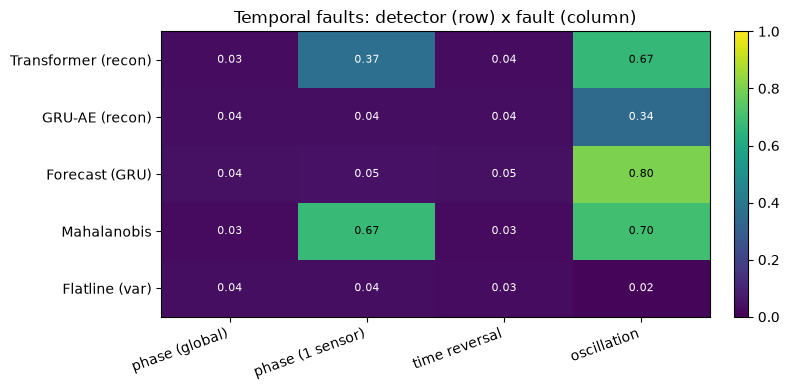

In [55]:
T = tempF.to_numpy(); rn = list(tempF.index); cn = list(tempF.columns)
fig, ax = plt.subplots(figsize=(8.0, 4.0))
im = ax.imshow(T, vmin=0, vmax=1, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(cn))); ax.set_xticklabels(cn, rotation=20, ha="right")
ax.set_yticks(range(len(rn))); ax.set_yticklabels(rn)
for i in range(len(rn)):
    for j in range(len(cn)):
        ax.text(j, i, f"{T[i, j]:.2f}", ha="center", va="center",
                color="white" if T[i, j] < 0.5 else "black", fontsize=8)
ax.set_title("Temporal faults: detector (row) x fault (column)")
plt.colorbar(im, fraction=0.046, pad=0.04); plt.tight_layout(); plt.show()

### Finding

**The deep nets win exactly one fault.** Phase shift & reversal fool everyone (no absolute-time feature); single-sensor phase → Mahalanobis (0.67); **oscillation → Forecast 0.80, Transformer 0.67** lead. No single detector wins — a portfolio does.

## Findings

**Framing.** Treating the Jena station as a 14-sensor IoT node changes both the task and the conclusions.
The realistic failure is a *single* sensor going bad while the other 13 stay normal — only 1/14 of the
network error — so detection now rewards models that understand **cross-sensor consistency**, not just
local spikiness.

**Early stopping never fired — these models don't overfit in 50 epochs.** With a chronological 80/20 split
and patience-5 early stopping (capped at 50 epochs), **every model's best validation epoch was epoch 50**:
the validation reconstruction loss was still falling at the cap, and for the Transformer and CNN the
**validation loss is ≈ or below the training loss** (Transformer val 0.0023 vs train 0.0038) — the exact
opposite of overfitting. *Discovery:* on this array these small autoencoders are **underfitting-limited, not
overfitting-limited** — the stopper is a safety net that simply never triggers here, and "train longer" keeps
helping (confirmed by the epoch sweep in Section C). Overfitting would only start to bite with bigger models,
far less data, or many more epochs.

**The headline — with 14 sensors, the Transformer wins (and by more, trained to 50 epochs).** At a hard 4σ
single-sensor fault the ranking is **Transformer AP 0.84 (F1 0.80) ≫ CNN 0.51 ≫ GRU 0.15 ≫ LSTM 0.09 ≈ RNN
0.05** — the *opposite* of the univariate single-series case, where a bottleneck CNN wins and the Transformer
trails.

- *Why.* Self-attention relates each sensor's reading to the other 13, so it flags a channel that is
  **inconsistent with its correlated neighbours** (humidity high while temperature/vapour-pressure disagree)
  even when that value isn't locally extreme. Univariately there are no neighbours to be inconsistent with,
  and the same expressive power instead lets the model copy its input; the CNN's local bottleneck was the
  right bias there. The Transformer also reconstructs the joint signal far better (loss 0.004 vs 0.07–0.16).
- *Discovery:* **the best architecture is task-dependent** — multivariate cross-sensor structure is exactly
  what attention is for, so the univariate ranking does not carry over.

**AUC hides what AP shows.** Every architecture scores ROC-AUC 0.99–1.00, which would rank them as identical;
**Average Precision** (the fair metric for ~100-in-70k rare events) spreads them ~15×. Reporting AUC alone
would have hidden the entire result — a reminder to pick the metric that matches the imbalance.

**Attribution is easier than detection — and nearly free.** Reading the **arg-max per-sensor error** names
*which* sensor faulted with **0.85–0.99 accuracy at 2σ, rising to ~1.0 by 4σ** for *every* architecture
(chance = 0.07) — including the RNN that barely *detects* subtle faults (AP 0.05). *Discovery:* localisation
is the easy half; once a fault is present the corrupted channel dominates its own reconstruction error
regardless of model, so the bottleneck for an IoT monitor is **noticing** the fault, not naming the sensor.
(The Transformer is marginally *lower* on attribution at 2–3σ — attention spreads error onto correlated
neighbours, so its arg-max occasionally names a neighbour.)

**Fair timing.** After a CUDA warm-up, 50 epochs took 1.2–2.1 s for all five. The **vanilla RNN is slow for
its size** (1.8 s at just 5.2k params, vs the GRU's 1.4 s at 12.5k) — cuDNN fuses GRU/LSTM kernels but the
plain RNN falls back to a sequential loop; the **Transformer is slowest overall** (2.1 s), paying for
attention. Param count ≠ wall-clock cost.

**Section C — a training choice can outweigh the architecture (again).**

- **Window size is the strongest single knob.** Shrinking the GRU window from 24 h to **12 h lifted AP 0.08
  → 0.77** — past the CNN (0.51) and approaching the Transformer (0.84) — while widening to 48 h collapsed it
  to 0.04. A short window reconstructs tightly (loss 0.07) so a fault stands out; a 48 h window averages the
  fault away (loss 0.33) and buries it.
- **More epochs only ever helped — no over-training turn-down.** GRU detection rose monotonically **AP 0.02
  (3 ep) → 0.09 (24 ep) → 0.15 (the 50-epoch early-stopped model)**. Under-training, not over-training, is
  the risk in this regime — which is exactly why the early stopper (Section A) ran to the cap.

**Section D — not all sensors are equal, and the correlation matrix predicted it.** Training a CNN on each
sensor alone, detectability spans two orders of magnitude: the tightly-coupled thermodynamic channels are
easy (**dew-point AP 0.999**; actual vapour pressure, specific humidity, water concentration and pressure
all 0.89–0.91), while the near-independent **wind** channels are almost unmodelable (**wind direction AP
0.009**, wind velocity 0.022, gust 0.031 — and the highest reconstruction losses, up to 0.19). *Discovery:*
a sensor's modelability tracks how strongly it correlates with the array — exactly the structure the
cross-sensor heatmap showed at the top. An IoT monitor built this way is sharp on its thermodynamic sensors
and effectively blind on its wind sensors.

**Trust note.** Every number here — losses, AUC/AP/F1, attribution accuracy, and the rankings — is computed
by PyTorch and scikit-learn. **No LLM (llama3b or otherwise) was consulted at any step.** Consistent with the
project principle: computation is the source of truth; the LLM elsewhere only *explains* numbers it is given,
it never produces them.

**Honest caveats.** The faults are *synthetic* single-sensor additive spikes (v1's known synthetic-label
limitation), so these rankings describe additive point-faults specifically — not slow drift, stuck sensors,
or correlated multi-sensor failures, which could favour different architectures. Early stopping monitors the
*validation reconstruction* loss (label-free) and here never triggered, so the reported models are the
50-epoch weights. The small default model sizes and un-tuned hyper-parameters are teaching choices, not
tuned state-of-the-art.

## Saving the trained models to disk

The models above live only in the kernel session — a **Restart & Run All** retrains them from scratch. To
reuse one later (in the app, another notebook, or a fresh kernel) we save two things per model: its learned
**weights** (`state_dict`) and the **per-sensor scaler** (`mu`, `sd`) it was trained with — without the same
scaler the scores would be meaningless. We save `state_dict`s (not whole pickled objects) because the model
classes are defined inline in this notebook; to reload you re-run the architecture cell to get the builders,
then pour the weights back in.

In [56]:
import json
MODELS_DIR = ROOT / 'v1' / 'notebooks' / 'saved_models_05'
MODELS_DIR.mkdir(exist_ok=True)

# 1) the scaler + config every model needs at inference time
np.savez(MODELS_DIR / 'standardiser.npz', mu=mu, sd=sd,
         window=WINDOW, sensors=np.array(SENSORS, dtype=object))
# 2) each model's learned weights
for name, m in models.items():
    torch.save(m.state_dict(), MODELS_DIR / f'{name}.pt')
# 3) a manifest tying it together (which builder rebuilds each file)
manifest = {'window': WINDOW, 'channels': S, 'sensors': SENSORS,
            'builders': {n: f'build_{n.lower()}_ae' for n in models},
            'files': {n: f'{n}.pt' for n in models}}
(MODELS_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2))

print('Saved to', MODELS_DIR)
for f in sorted(MODELS_DIR.iterdir()):
    print(f'  {f.name:20s} {f.stat().st_size/1024:6.1f} KB')

Saved to /home/saizer/Documents/Msc_project/code/v1/notebooks/saved_models_05
  CNN.pt                 48.4 KB
  GRU.pt                 52.3 KB
  LSTM.pt                66.5 KB
  RNN.pt                 23.8 KB
  Transformer.pt        145.1 KB
  manifest.json           0.6 KB
  standardiser.npz        1.4 KB


### Reloading a saved model (and proving it's the same)

In a fresh kernel you would first **Run All the harness + architecture cells** (they define `build_*`,
`apply_standardise`, `recon_error_matrix`, `network_score`), then run the code below. Here we reload the
Transformer and confirm its scores match the in-memory model exactly.

In [57]:
ckpt = np.load(MODELS_DIR / 'standardiser.npz', allow_pickle=True)
mu2, sd2, win2 = ckpt['mu'], ckpt['sd'], int(ckpt['window'])

reloaded = build_transformer_ae(win2, S)                       # rebuild the architecture
reloaded.load_state_dict(torch.load(MODELS_DIR / 'Transformer.pt'))   # pour the weights in
reloaded.to(DEVICE).eval()

a = network_score(recon_error_matrix(models['Transformer'], Z, WINDOW))       # in-memory model
b = network_score(recon_error_matrix(reloaded, apply_standardise(df, mu2, sd2), win2))  # reloaded
print('reloaded model reproduces the in-memory scores exactly:', bool(np.allclose(a, b, atol=1e-5)))

reloaded model reproduces the in-memory scores exactly: True


## Appendix — Try it yourself

The models trained above live in the `models` dict for the rest of the kernel session. After a **Restart &
Run All**, edit the two knobs below and re-run *just this cell* to (1) score any slice of the data
unsupervised — with the guilty sensor named — and (2) measure detection on a fault you inject yourself.
(These models are notebook-only and not saved to disk; to persist one, see the note under the notebook.)

In [58]:
MODEL_NAME = "Transformer"     # one of: "RNN", "GRU", "LSTM", "CNN", "Transformer"
PERIOD     = "2015"            # any year / month / slice, e.g. "2015-08"
# =====================================================================================
model = models[MODEL_NAME]

# --- 1) Score a real slice of the data (unsupervised: no labels needed) ---
sub   = df.loc[PERIOD]
Zsub  = apply_standardise(sub, mu, sd)              # SAME per-sensor scaler the model trained on
err   = recon_error_matrix(model, Zsub, WINDOW)     # per-sensor error  [T, 14]
score = network_score(err)                          # one anomaly score per hour
thr   = np.quantile(score, 0.995)                   # flag the top 0.5% most-anomalous hours
flag  = score > thr
guilty = err.argmax(axis=1)                         # which sensor drove each alarm
print(f"[{MODEL_NAME}] scored {len(sub)} hours of {PERIOD}: {int(flag.sum())} flagged (top 0.5%).")
print("First 10 alarms (time -> most-anomalous sensor):")
for t in np.where(flag)[0][:10]:
    print(f"  {sub.index[t]}  score={score[t]:5.2f}  ->  {SENSORS[guilty[t]]}")

# --- 2) Test it on a KNOWN fault you inject yourself (measurable) ---
mag = 4.0
noisy, labels, fault = inject_sensor_faults(df, n=100, magnitude=mag, seed=7)
err2 = recon_error_matrix(model, apply_standardise(noisy, mu, sd), WINDOW)
sc   = network_score(err2)
N    = int(labels.sum()); pred = sc >= np.sort(sc)[-N]
idx  = np.where(labels)[0]
attr = float((err2[idx].argmax(axis=1) == fault[idx]).mean())
print(f"\nInjected 100 faults @ {mag} sigma  ->  AP={average_precision_score(labels, sc):.3f}, "
      f"caught {int((pred & labels).sum())}/{N} in the top-N, correct-sensor attribution={attr:.2f}")

[Transformer] scored 8760 hours of 2015: 44 flagged (top 0.5%).
First 10 alarms (time -> most-anomalous sensor):
  2015-07-03 15:00:00  score= 0.07  ->  VPdef (mbar)
  2015-07-03 16:00:00  score= 0.08  ->  VPdef (mbar)
  2015-07-04 11:00:00  score= 0.06  ->  VPdef (mbar)
  2015-07-04 12:00:00  score= 0.17  ->  VPdef (mbar)
  2015-07-04 13:00:00  score= 0.29  ->  VPdef (mbar)
  2015-07-04 14:00:00  score= 0.39  ->  VPdef (mbar)
  2015-07-04 15:00:00  score= 0.54  ->  VPdef (mbar)
  2015-07-04 16:00:00  score= 0.67  ->  VPdef (mbar)
  2015-07-04 17:00:00  score= 0.50  ->  VPdef (mbar)
  2015-07-04 18:00:00  score= 0.26  ->  VPdef (mbar)

Injected 100 faults @ 4.0 sigma  ->  AP=0.787, caught 72/100 in the top-N, correct-sensor attribution=0.95
